In [2]:
%pip install duckdb pandas matplotlib

  Using cached duckdb-1.5.6-cp314-cp314-macosx_10_15_x86_64.whl.metadata (4.2 kB)
  Using cached pandas-3.0.6-cp314-cp314-macosx_10_15_x86_64.whl.metadata (79 kB)
  Using cached matplotlib-3.11.2-cp314-cp314-macosx_10_15_x86_64.whl.metadata (80 kB)
  Using cached numpy-2.5.3-cp314-cp314-macosx_14_0_x86_64.whl.metadata (6.6 kB)
  Using cached contourpy-1.4.0-cp314-cp314-macosx_10_15_x86_64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.66.1-cp314-cp314-macosx_10_15_x86_64.whl.metadata (130 kB)
  Using cached kiwisolver-1.5.1-cp314-cp314-macosx_10_15_x86_64.whl.metadata (5.2 kB)
  Using cached pillow-12.3.0-cp314-cp314-macosx_10_15_x86_64.whl.metadata (9.1 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached duckdb-1.5.6-cp314-cp314-macosx_10_15_x86_64.whl (17.4 MB)
Using cached pandas-3.0.6-cp314-cp314-macosx_10_15_x86_64.whl (10.5 MB)
Using cached matplotlib-3.11.2-cp314-cp314-macosx_10_15_x

In [4]:
from pathlib import Path

ROOT = Path.cwd()
db_path = ROOT / "lakehouse.duckdb"

print("Project root:", ROOT)
print("Database exists:", db_path.exists())

if db_path.exists():
    print("Database size:", db_path.stat().st_size, "bytes")

Project root: /Users/maha/Desktop/assignment-starter-repo/assign1
Database exists: True
Database size: 0 bytes


In [5]:
from pathlib import Path
import duckdb

ROOT = Path.cwd()
db_path = ROOT / "lakehouse.duckdb"

con = duckdb.connect(str(db_path))

print("Database created:", db_path)
print("Test query:", con.execute("SELECT 1 AS test").fetchall())

Database created: /Users/maha/Desktop/assignment-starter-repo/assign1/lakehouse.duckdb
Test query: [(1,)]


In [6]:
DATA_RAW = ROOT / "data" / "raw"

baci_files = sorted(
    f for f in DATA_RAW.rglob("*.csv")
    if "baci" in str(f).lower()
)

print("BACI files found:", len(baci_files))

for f in baci_files[:10]:
    print(f.relative_to(ROOT))

BACI files found: 10
data/raw/BACI_HS17/BACI_HS17_Y2017_V202601.csv
data/raw/BACI_HS17/BACI_HS17_Y2018_V202601.csv
data/raw/BACI_HS17/BACI_HS17_Y2019_V202601.csv
data/raw/BACI_HS17/BACI_HS17_Y2020_V202601.csv
data/raw/BACI_HS17/BACI_HS17_Y2021_V202601.csv
data/raw/BACI_HS17/BACI_HS17_Y2022_V202601.csv
data/raw/BACI_HS17/BACI_HS17_Y2023_V202601.csv
data/raw/BACI_HS17/BACI_HS17_Y2024_V202601.csv
data/raw/BACI_HS17/country_codes_V202601.csv
data/raw/BACI_HS17/product_codes_HS17_V202601.csv


In [7]:
import pandas as pd
from datetime import datetime, timezone
from pathlib import Path
import uuid

# One ID for this ingestion run
load_id = str(uuid.uuid4())
ingested_at = datetime.now(timezone.utc).isoformat()

load_report = []
bronze_frames = []

for file in baci_files:
    print("Loading:", file.name)

    # Read the source CSV
    df = pd.read_csv(file)

    # Preserve original columns and add ingestion metadata
    df["source_name"] = file.name
    df["ingested_at"] = ingested_at
    df["load_id"] = load_id

    bronze_frames.append(df)

    load_report.append({
        "source_name": file.name,
        "load_id": load_id,
        "ingested_at": ingested_at,
        "input_row_count": len(df)
    })

# Combine all yearly records
bronze_df = pd.concat(bronze_frames, ignore_index=True)

# Save to DuckDB
con.register("bronze_input", bronze_df)

con.execute("""
    CREATE OR REPLACE TABLE bronze_trade AS
    SELECT * FROM bronze_input
""")

con.unregister("bronze_input")

# Save a Parquet copy of Bronze
con.execute("""
    COPY bronze_trade
    TO 'data/bronze/bronze_trade.parquet'
    (FORMAT PARQUET)
""")

# Save ingestion report
load_report_df = pd.DataFrame(load_report)
load_report_df.to_csv(
    "outputs/reports/load_report.csv",
    index=False
)

print("Bronze ingestion complete.")
print("Total input rows:", len(bronze_df))
print("Bronze table rows:", con.execute(
    "SELECT COUNT(*) FROM bronze_trade"
).fetchone()[0])
print("Files loaded:", len(load_report_df))

Loading: BACI_HS17_Y2017_V202601.csv
Loading: BACI_HS17_Y2018_V202601.csv
Loading: BACI_HS17_Y2019_V202601.csv
Loading: BACI_HS17_Y2020_V202601.csv
Loading: BACI_HS17_Y2021_V202601.csv
Loading: BACI_HS17_Y2022_V202601.csv
Loading: BACI_HS17_Y2023_V202601.csv
Loading: BACI_HS17_Y2024_V202601.csv
Loading: country_codes_V202601.csv
Loading: product_codes_HS17_V202601.csv
Bronze ingestion complete.
Total input rows: 89212843
Bronze table rows: 89212843
Files loaded: 10


In [10]:
# Inspect Bronze column names and data types
print("BRONZE SCHEMA:")
print(con.execute("DESCRIBE bronze_trade").df())

print("\nCOUNTRY AND PRODUCT LOOKUP FILES:")
for f in DATA_RAW.rglob("*.csv"):
    name = f.name.lower()
    if "country" in name or "product" in name or "code" in name:
        print(f.relative_to(ROOT))

BRONZE SCHEMA:
     column_name column_type null   key default extra
0              t      DOUBLE  YES  None    None  None
1              i      DOUBLE  YES  None    None  None
2              j      DOUBLE  YES  None    None  None
3              k      DOUBLE  YES  None    None  None
4              v      DOUBLE  YES  None    None  None
5              q      DOUBLE  YES  None    None  None
6    source_name     VARCHAR  YES  None    None  None
7    ingested_at     VARCHAR  YES  None    None  None
8        load_id     VARCHAR  YES  None    None  None
9   country_code      DOUBLE  YES  None    None  None
10  country_name     VARCHAR  YES  None    None  None
11  country_iso2     VARCHAR  YES  None    None  None
12  country_iso3     VARCHAR  YES  None    None  None
13          code      DOUBLE  YES  None    None  None
14   description     VARCHAR  YES  None    None  None

COUNTRY AND PRODUCT LOOKUP FILES:
data/raw/BACI_HS17/product_codes_HS17_V202601.csv
data/raw/BACI_HS17/country_codes_V20

In [11]:
# 1. Confirm the actual Bronze columns
print("BRONZE COLUMNS:")
print(con.execute("DESCRIBE bronze_trade").df()["column_name"].tolist())

# 2. Find the country and product lookup CSVs
print("\nLOOKUP FILES:")
for f in DATA_RAW.rglob("*.csv"):
    name = f.name.lower()
    if "country" in name or "product" in name or "code" in name:
        print(f)

# 3. Show the load report
print("\nLOAD REPORT:")
print(pd.read_csv("outputs/reports/load_report.csv").head())

BRONZE COLUMNS:
['t', 'i', 'j', 'k', 'v', 'q', 'source_name', 'ingested_at', 'load_id', 'country_code', 'country_name', 'country_iso2', 'country_iso3', 'code', 'description']

LOOKUP FILES:
/Users/maha/Desktop/assignment-starter-repo/assign1/data/raw/BACI_HS17/product_codes_HS17_V202601.csv
/Users/maha/Desktop/assignment-starter-repo/assign1/data/raw/BACI_HS17/country_codes_V202601.csv

LOAD REPORT:
                   source_name                               load_id  \
0  BACI_HS17_Y2017_V202601.csv  579d44e0-a258-4c05-99ca-cc3152b22bc5   
1  BACI_HS17_Y2018_V202601.csv  579d44e0-a258-4c05-99ca-cc3152b22bc5   
2  BACI_HS17_Y2019_V202601.csv  579d44e0-a258-4c05-99ca-cc3152b22bc5   
3  BACI_HS17_Y2020_V202601.csv  579d44e0-a258-4c05-99ca-cc3152b22bc5   
4  BACI_HS17_Y2021_V202601.csv  579d44e0-a258-4c05-99ca-cc3152b22bc5   

                        ingested_at  input_row_count  
0  2026-10-10T12:55:46.789919+00:00          9948845  
1  2026-10-10T12:55:46.789919+00:00         10802500  

In [12]:
from pathlib import Path
import pandas as pd

for f in DATA_RAW.rglob("*.csv"):
    filename = f.name.lower()

    if "country" in filename or "product" in filename or "code" in filename:
        print("\nFILE:", f)
        df = pd.read_csv(f, nrows=5)
        print("COLUMNS:", df.columns.tolist())
        print(df.head(2))


FILE: /Users/maha/Desktop/assignment-starter-repo/assign1/data/raw/BACI_HS17/product_codes_HS17_V202601.csv
COLUMNS: ['code', 'description']
    code                                        description
0  10121           Horses: live, pure-bred breeding animals
1  10129  Horses: live, other than pure-bred breeding an...

FILE: /Users/maha/Desktop/assignment-starter-repo/assign1/data/raw/BACI_HS17/country_codes_V202601.csv
COLUMNS: ['country_code', 'country_name', 'country_iso2', 'country_iso3']
   country_code country_name country_iso2 country_iso3
0             4  Afghanistan           AF          AFG
1             8      Albania           AL          ALB


silver next

In [15]:
for f in DATA_RAW.rglob("*.csv"):
    if "country_codes" in str(f).lower():
        countries = pd.read_csv(f, nrows=5)
        countries.columns = countries.columns.str.strip()

        print("Country file:", f)
        print("Columns:", [repr(c) for c in countries.columns])
        print("First rows:")
        print(countries.head(2))
        break


Country file: /Users/maha/Desktop/assignment-starter-repo/assign1/data/raw/BACI_HS17/country_codes_V202601.csv
Columns: ["'country_code'", "'country_name'", "'country_iso2'", "'country_iso3'"]
First rows:
   country_code country_name country_iso2 country_iso3
0             4  Afghanistan           AF          AFG
1             8      Albania           AL          ALB


In [16]:
print(countries.columns.tolist())

['country_code', 'country_name', 'country_iso2', 'country_iso3']


In [17]:
# Normalize country and product lookup column names
countries.columns = countries.columns.str.strip().str.lower()
products.columns = products.columns.str.strip().str.lower()

print("Country columns:", countries.columns.tolist())
print("Product columns:", products.columns.tolist())

Country columns: ['country_code', 'country_name', 'country_iso2', 'country_iso3']
Product columns: ['code', 'description']


In [18]:

# Clean lookup column names
countries.columns = countries.columns.str.strip().str.lower()
products.columns = products.columns.str.strip().str.lower()

# Normalize lookup key types
countries["country_code"] = pd.to_numeric(
    countries["country_code"], errors="raise"
).astype("int64")

products["code"] = products["code"].astype(str).str.strip()

# Register lookup tables in DuckDB
con.register("country_lookup_df", countries)
con.register("product_lookup_df", products)

# Build Silver: Qatar imports (importer code 634)
con.execute("""
    CREATE OR REPLACE TABLE silver_trade AS
    SELECT
        TRY_CAST(b.t AS INTEGER) AS year,
        TRY_CAST(b.j AS INTEGER) AS exporter_code,
        TRY_CAST(b.i AS INTEGER) AS importer_code,
        CAST(b.k AS VARCHAR) AS product_code,
        TRY_CAST(b.v AS DOUBLE) AS trade_value,
        TRY_CAST(b.q AS DOUBLE) AS quantity,
        ec.name AS exporter_name,
        ic.name AS importer_name,
        ic.iso2 AS importer_iso2,
        ic.iso3 AS importer_iso3,
        p.description AS product_description,
        b.source_name,
        b.ingested_at,
        b.load_id
    FROM bronze_trade b
    LEFT JOIN country_lookup_df ec
        ON TRY_CAST(b.j AS INTEGER) = ec.country_code
    LEFT JOIN country_lookup_df ic
        ON TRY_CAST(b.i AS INTEGER) = ic.country_code
    LEFT JOIN product_lookup_df p
        ON CAST(b.k AS VARCHAR) = p.code
    WHERE TRY_CAST(b.i AS INTEGER) = 634
""")

# Remove temporary registrations
con.unregister("country_lookup_df")
con.unregister("product_lookup_df")

# Save Silver as Parquet
con.execute("""
    COPY silver_trade
    TO 'data/silver/silver_trade.parquet'
    (FORMAT PARQUET)
""")

# Verify the result
print("Silver rows:",
      con.execute("SELECT COUNT(*) FROM silver_trade").fetchone()[0])

con.execute("""
    SELECT *
    FROM silver_trade
    LIMIT 5
""").df()

BinderException: Binder Error: Values list "ec" does not have a column named "name"

LINE 10:         ec.name AS exporter_name,
                 ^

In [24]:
print("Country DataFrame columns:", countries.columns.tolist())
print("Product DataFrame columns:", products.columns.tolist())

print("\nCountry lookup preview:")
print(countries.head(3))

print("\nCountry lookup data types:")
print(countries.dtypes)

Country DataFrame columns: ['country_code', 'country_name', 'country_iso2', 'country_iso3']
Product DataFrame columns: ['code', 'description']

Country lookup preview:
   country_code country_name country_iso2 country_iso3
0             4  Afghanistan           AF          AFG
1             8      Albania           AL          ALB
2            12      Algeria           DZ          DZA

Country lookup data types:
country_code    int64
country_name      str
country_iso2      str
country_iso3      str
dtype: object


In [25]:
# Make a clean copy with explicit column names
country_lookup = countries.copy()
country_lookup.columns = [
    str(c).strip().lower() for c in country_lookup.columns
]

print(country_lookup.columns.tolist())

['country_code', 'country_name', 'country_iso2', 'country_iso3']


In [26]:
# Remove a previous registration if it exists
try:
    con.unregister("country_lookup_df")
except Exception:
    pass

con.register("country_lookup_df", country_lookup)

print(
    con.execute("DESCRIBE country_lookup_df").df()
)

    column_name column_type null   key default extra
0  country_code      BIGINT  YES  None    None  None
1  country_name     VARCHAR  YES  None    None  None
2  country_iso2     VARCHAR  YES  None    None  None
3  country_iso3     VARCHAR  YES  None    None  None


In [27]:
print(
    con.execute("DESCRIBE country_lookup_df").df()["column_name"].tolist()
)

['country_code', 'country_name', 'country_iso2', 'country_iso3']


In [29]:

# Prepare product lookup
product_lookup = products.copy()
product_lookup.columns = [
    str(c).strip().lower() for c in product_lookup.columns
]

# Ensure lookup keys use compatible types
country_lookup["country_code"] = pd.to_numeric(
    country_lookup["country_code"], errors="coerce"
).astype("Int64")

product_lookup["code"] = (
    product_lookup["code"].astype(str).str.strip()
)

# Register the product lookup
try:
    con.unregister("product_lookup_df")
except Exception:
    pass

con.register("product_lookup_df", product_lookup)

# Create the Silver table
con.execute("""
    CREATE OR REPLACE TABLE silver_trade AS
    SELECT
        TRY_CAST(b.t AS INTEGER) AS year,
        TRY_CAST(b.j AS INTEGER) AS exporter_code,
        TRY_CAST(b.i AS INTEGER) AS importer_code,
        CAST(b.k AS VARCHAR) AS product_code,
        TRY_CAST(b.v AS DOUBLE) AS trade_value,
        TRY_CAST(b.q AS DOUBLE) AS quantity,
        ec.name AS exporter_name,
        ic.name AS importer_name,
        ic.iso2 AS importer_iso2,
        ic.iso3 AS importer_iso3,
        p.description AS product_description,
        b.source_name,
        b.ingested_at,
        b.load_id
    FROM bronze_trade b
    LEFT JOIN country_lookup_df ec
        ON TRY_CAST(b.j AS BIGINT) = ec.country_code
    LEFT JOIN country_lookup_df ic
        ON TRY_CAST(b.i AS BIGINT) = ic.country_code
    LEFT JOIN product_lookup_df p
        ON CAST(b.k AS VARCHAR) = p.code
    WHERE TRY_CAST(b.i AS INTEGER) = 634
""")

# Save Silver
con.execute("""
    COPY silver_trade
    TO 'data/silver/silver_trade.parquet'
    (FORMAT PARQUET)
""")

# Verify the result
print("Silver row count:",
      con.execute("SELECT COUNT(*) FROM silver_trade").fetchone()[0])

print("\nSample rows:")
print(con.execute("""
    SELECT year, exporter_name, importer_name,
           product_code, product_description,
           trade_value, quantity
    FROM silver_trade
    LIMIT 5
""").df())

BinderException: Binder Error: Values list "ec" does not have a column named "name"

LINE 10:         ec.name AS exporter_name,
                 ^

In [30]:
# Inspect the country lookup DuckDB actually sees
print("Registered country lookup:")
print(con.execute("""
    SELECT *
    FROM country_lookup_df
    LIMIT 3
""").df())

print("\nCountry lookup schema:")
print(con.execute("""
    DESCRIBE country_lookup_df
""").df())

print("\nProduct lookup schema:")
print(con.execute("""
    DESCRIBE product_lookup_df
""").df())

Registered country lookup:
   country_code country_name country_iso2 country_iso3
0             4  Afghanistan           AF          AFG
1             8      Albania           AL          ALB
2            12      Algeria           DZ          DZA

Country lookup schema:
    column_name column_type null   key default extra
0  country_code      BIGINT  YES  None    None  None
1  country_name     VARCHAR  YES  None    None  None
2  country_iso2     VARCHAR  YES  None    None  None
3  country_iso3     VARCHAR  YES  None    None  None

Product lookup schema:
   column_name column_type null   key default extra
0         code     VARCHAR  YES  None    None  None
1  description     VARCHAR  YES  None    None  None


In [31]:
print("Country lookup columns:")
print(con.execute("DESCRIBE country_lookup_df").df()["column_name"].tolist())

print("\nProduct lookup columns:")
print(con.execute("DESCRIBE product_lookup_df").df()["column_name"].tolist())

print("\nBronze columns:")
print(con.execute("DESCRIBE bronze_trade").df()["column_name"].tolist())

Country lookup columns:
['country_code', 'country_name', 'country_iso2', 'country_iso3']

Product lookup columns:
['code', 'description']

Bronze columns:
['t', 'i', 'j', 'k', 'v', 'q', 'source_name', 'ingested_at', 'load_id', 'country_code', 'country_name', 'country_iso2', 'country_iso3', 'code', 'description']


In [32]:
for table in [
    "country_lookup_df",
    "product_lookup_df",
    "bronze_trade"
]:
    print(f"\n{table}:")
    print([
        row[0]
        for row in con.execute(
            f"DESCRIBE {table}"
        ).fetchall()
    ])


country_lookup_df:
['country_code', 'country_name', 'country_iso2', 'country_iso3']

product_lookup_df:
['code', 'description']

bronze_trade:
['t', 'i', 'j', 'k', 'v', 'q', 'source_name', 'ingested_at', 'load_id', 'country_code', 'country_name', 'country_iso2', 'country_iso3', 'code', 'description']


In [33]:
print("Country lookup test:")
print(con.execute("""
    SELECT country_code, name, iso2, iso3
    FROM country_lookup_df
    LIMIT 3
""").df())

print("\nProduct lookup test:")
print(con.execute("""
    SELECT code, description
    FROM product_lookup_df
    LIMIT 3
""").df())

Country lookup test:


BinderException: Binder Error: Referenced column "name" not found in FROM clause!
Candidate bindings: "country_code"

LINE 2:     SELECT country_code, name, iso2, iso3
                                 ^

In [34]:
# Show the actual country DataFrame columns
print(countries.columns.tolist())

['country_code', 'country_name', 'country_iso2', 'country_iso3']


In [35]:
# Create a clean country lookup with a new explicit name column
country_lookup_clean = countries.copy()
country_lookup_clean.columns = [
    str(c).strip().lower() for c in country_lookup_clean.columns
]

country_lookup_clean = country_lookup_clean.rename(
    columns={"name": "country_name"}
)

# Register under a fresh name
try:
    con.unregister("country_lookup_clean_df")
except Exception:
    pass

con.register("country_lookup_clean_df", country_lookup_clean)

print(con.execute("""
    SELECT country_code, country_name, iso2, iso3
    FROM country_lookup_clean_df
    LIMIT 3
""").df())

BinderException: Binder Error: Referenced column "iso2" not found in FROM clause!
Candidate bindings: "country_code"

LINE 2:     SELECT country_code, country_name, iso2, iso3
                                               ^

In [36]:
from pathlib import Path
import pandas as pd

for f in DATA_RAW.rglob("*.csv"):
    if "country_codes" in str(f).lower():
        check = pd.read_csv(f, nrows=3)
        print("FILE:", f)
        print("COLUMNS:", [repr(c) for c in check.columns])
        print("FIRST ROWS:")
        print(check.to_string(index=False))
        break

FILE: /Users/maha/Desktop/assignment-starter-repo/assign1/data/raw/BACI_HS17/country_codes_V202601.csv
COLUMNS: ["'country_code'", "'country_name'", "'country_iso2'", "'country_iso3'"]
FIRST ROWS:
 country_code country_name country_iso2 country_iso3
            4  Afghanistan           AF          AFG
            8      Albania           AL          ALB
           12      Algeria           DZ          DZA


In [37]:
print("Registered lookup schema:")
print(con.execute(
    "DESCRIBE country_lookup_clean_df"
).fetchall())

Registered lookup schema:
[('country_code', 'BIGINT', 'YES', None, None, None), ('country_name', 'VARCHAR', 'YES', None, None, None), ('country_iso2', 'VARCHAR', 'YES', None, None, None), ('country_iso3', 'VARCHAR', 'YES', None, None, None)]


In [38]:
# Reload the original country CSV using its actual path
country_file = next(
    f for f in DATA_RAW.rglob("*.csv")
    if "country_codes" in str(f).lower()
)

countries = pd.read_csv(country_file)

# Normalize column names
countries.columns = countries.columns.str.strip().str.lower()

print("Original CSV columns:", countries.columns.tolist())

Original CSV columns: ['country_code', 'country_name', 'country_iso2', 'country_iso3']


In [39]:
# Use a fresh registration name to avoid stale references
try:
    con.unregister("country_lookup_final")
except Exception:
    pass

con.register("country_lookup_final", countries)

print(con.execute("""
    SELECT *
    FROM country_lookup_final
    LIMIT 3
""").df())

   country_code country_name country_iso2 country_iso3
0             4  Afghanistan           AF          AFG
1             8      Albania           AL          ALB
2            12      Algeria           DZ          DZA


In [42]:
print("Country columns:", countries.columns.tolist())
print("Registered country lookup:")
print(con.execute(
    "DESCRIBE country_lookup_final"
).df()["column_name"].tolist())

Country columns: ['country_code', 'country_name', 'country_iso2', 'country_iso3']
Registered country lookup:
['country_code', 'country_name', 'country_iso2', 'country_iso3']


In [43]:
countries.columns = (
    countries.columns.astype(str).str.strip().str.lower()
)

rename_map = {}

for col in countries.columns:
    normalized = col.replace("_", "").replace(" ", "")

    if normalized in ["countrycode", "code"]:
        rename_map[col] = "country_code"
    elif normalized in ["countryname", "name"]:
        rename_map[col] = "country_name"
    elif normalized == "iso2":
        rename_map[col] = "iso2"
    elif normalized == "iso3":
        rename_map[col] = "iso3"

countries = countries.rename(columns=rename_map)

print("Standardized columns:", countries.columns.tolist())

Standardized columns: ['country_code', 'country_name', 'country_iso2', 'country_iso3']


In [44]:
print("Country columns:", countries.columns.tolist())

# Show only the country code and country name columns
print(
    countries[["country_code", "country_name"]].head(5)
)

Country columns: ['country_code', 'country_name', 'country_iso2', 'country_iso3']
   country_code    country_name
0             4     Afghanistan
1             8         Albania
2            12         Algeria
3            16  American Samoa
4            20         Andorra


In [45]:

# SILVER: Qatar import records with country and product descriptions

# Reload the product lookup from the actual CSV
product_file = next(
    f for f in DATA_RAW.rglob("*.csv")
    if "product_codes" in str(f).lower()
)

products = pd.read_csv(product_file)
products.columns = products.columns.str.strip().str.lower()

# Check the required columns
assert "code" in products.columns, products.columns.tolist()
assert "description" in products.columns, products.columns.tolist()

# Normalize lookup keys
countries["country_code"] = pd.to_numeric(
    countries["country_code"], errors="coerce"
).astype("Int64")

products["code"] = pd.to_numeric(
    products["code"], errors="coerce"
).astype("Int64")

# Register fresh lookup tables
for name in ["silver_country", "silver_product"]:
    try:
        con.unregister(name)
    except Exception:
        pass

con.register("silver_country", countries)
con.register("silver_product", products)

# Create Silver table
con.execute("""
    CREATE OR REPLACE TABLE silver_trade AS
    SELECT
        TRY_CAST(b.t AS INTEGER) AS year,
        TRY_CAST(b.j AS INTEGER) AS exporter_code,
        TRY_CAST(b.i AS INTEGER) AS importer_code,
        TRY_CAST(b.k AS BIGINT) AS product_code,
        TRY_CAST(b.v AS DOUBLE) AS trade_value,
        TRY_CAST(b.q AS DOUBLE) AS quantity,
        ec.country_name AS exporter_name,
        ic.country_name AS importer_name,
        p.description AS product_description,
        b.source_name,
        b.ingested_at,
        b.load_id
    FROM bronze_trade AS b
    LEFT JOIN silver_country AS ec
        ON TRY_CAST(b.j AS BIGINT) = ec.country_code
    LEFT JOIN silver_country AS ic
        ON TRY_CAST(b.i AS BIGINT) = ic.country_code
    LEFT JOIN silver_product AS p
        ON TRY_CAST(b.k AS BIGINT) = p.code
    WHERE TRY_CAST(b.i AS INTEGER) = 634
""")

# Save Silver to Parquet
con.execute("""
    COPY silver_trade
    TO 'data/silver/silver_trade.parquet'
    (FORMAT PARQUET)
""")

# Verify the result
print("Silver rows:",
      con.execute("SELECT COUNT(*) FROM silver_trade").fetchone()[0])

print(con.execute("""
    SELECT year, exporter_name, importer_name,
           product_code, product_description,
           trade_value, quantity
    FROM silver_trade
    LIMIT 5
""").df())

Silver rows: 111928
   year exporter_name importer_name  product_code  \
0  2017       Albania         Qatar        390110   
1  2017       Algeria         Qatar        381590   
2  2017       Algeria         Qatar        381700   
3  2017       Algeria         Qatar        382440   
4  2017       Algeria         Qatar        390110   

                                 product_description  trade_value   quantity  
0  Ethylene polymers: in primary forms, polyethyl...     1364.570   1122.000  
1  Reaction initiators, reaction accelerators and...       11.076      0.460  
2  Mixed alkylbenzenes and mixed alkylnaphthalene...     6197.115   4560.000  
3  Cements, mortars or concretes: their prepared ...        0.176      0.061  
4  Ethylene polymers: in primary forms, polyethyl...    21335.409  16173.195  


In [46]:
# Silver data-quality checks

print("1. Total Silver rows:")
print(con.execute("""
    SELECT COUNT(*) FROM silver_trade
""").fetchone()[0])

print("\n2. Rows by year:")
print(con.execute("""
    SELECT year, COUNT(*) AS rows
    FROM silver_trade
    GROUP BY year
    ORDER BY year
""").df())

print("\n3. Missing exporter names:")
print(con.execute("""
    SELECT COUNT(*)
    FROM silver_trade
    WHERE exporter_name IS NULL
""").fetchone()[0])

print("\n4. Missing product descriptions:")
print(con.execute("""
    SELECT COUNT(*)
    FROM silver_trade
    WHERE product_description IS NULL
""").fetchone()[0])

print("\n5. Missing quantities:")
print(con.execute("""
    SELECT COUNT(*)
    FROM silver_trade
    WHERE quantity IS NULL
""").fetchone()[0])

print("\n6. Negative trade values:")
print(con.execute("""
    SELECT COUNT(*)
    FROM silver_trade
    WHERE trade_value < 0
""").fetchone()[0])

print("\n7. Duplicate trade records:")
print(con.execute("""
    SELECT COUNT(*) FROM (
        SELECT year, exporter_code, importer_code,
               product_code, trade_value, quantity
        FROM silver_trade
        GROUP BY year, exporter_code, importer_code,
                 product_code, trade_value, quantity
        HAVING COUNT(*) > 1
    ) AS duplicates
""").fetchone()[0])

1. Total Silver rows:
111928

2. Rows by year:
   year   rows
0  2017   9480
1  2018  12714
2  2019  13632
3  2020  13678
4  2021  16167
5  2022  16854
6  2023  16672
7  2024  12731

3. Missing exporter names:
0

4. Missing product descriptions:
0

5. Missing quantities:
6686

6. Negative trade values:
0

7. Duplicate trade records:
0


In [47]:

from pathlib import Path
import pandas as pd

# Collect Silver quality metrics
quality_checks = con.execute("""
    SELECT 'total_rows' AS check_name,
           COUNT(*) AS result
    FROM silver_trade

    UNION ALL

    SELECT 'missing_exporter_name',
           COUNT(*) FILTER (WHERE exporter_name IS NULL)
    FROM silver_trade

    UNION ALL

    SELECT 'missing_product_description',
           COUNT(*) FILTER (WHERE product_description IS NULL)
    FROM silver_trade

    UNION ALL

    SELECT 'missing_quantity',
           COUNT(*) FILTER (WHERE quantity IS NULL)
    FROM silver_trade

    UNION ALL

    SELECT 'negative_trade_value',
           COUNT(*) FILTER (WHERE trade_value < 0)
    FROM silver_trade

    UNION ALL

    SELECT 'negative_quantity',
           COUNT(*) FILTER (WHERE quantity < 0)
    FROM silver_trade
""").df()

# Save report
Path("outputs/reports").mkdir(parents=True, exist_ok=True)

quality_checks.to_csv(
    "outputs/reports/silver_quality_report.csv",
    index=False
)

print("Silver quality report saved.")
print(quality_checks)

print("\nSilver rows by year:")
print(con.execute("""
    SELECT year, COUNT(*) AS row_count
    FROM silver_trade
    GROUP BY year
    ORDER BY year
""").df())

Silver quality report saved.
                    check_name  result
0                   total_rows  111928
1        missing_exporter_name       0
2  missing_product_description       0
3             missing_quantity    6686
4         negative_trade_value       0
5            negative_quantity       0

Silver rows by year:
   year  row_count
0  2017       9480
1  2018      12714
2  2019      13632
3  2020      13678
4  2021      16167
5  2022      16854
6  2023      16672
7  2024      12731


gold star schema next

In [48]:

from pathlib import Path

Path("data/gold").mkdir(parents=True, exist_ok=True)

# 1. Dimension: Year
con.execute("""
    CREATE OR REPLACE TABLE dim_year AS
    SELECT DISTINCT
        year,
        CAST(year AS VARCHAR) AS year_label
    FROM silver_trade
    WHERE year IS NOT NULL
""")

# 2. Dimension: Exporter country
con.execute("""
    CREATE OR REPLACE TABLE dim_exporter AS
    SELECT DISTINCT
        exporter_code,
        exporter_name
    FROM silver_trade
    WHERE exporter_code IS NOT NULL
""")

# 3. Dimension: Product
con.execute("""
    CREATE OR REPLACE TABLE dim_product AS
    SELECT DISTINCT
        product_code,
        product_description
    FROM silver_trade
    WHERE product_code IS NOT NULL
""")

# 4. Dimension: Importer country
con.execute("""
    CREATE OR REPLACE TABLE dim_importer AS
    SELECT DISTINCT
        importer_code,
        importer_name
    FROM silver_trade
    WHERE importer_code IS NOT NULL
""")

# 5. Fact table
con.execute("""
    CREATE OR REPLACE TABLE fact_trade AS
    SELECT
        s.year,
        s.exporter_code,
        s.importer_code,
        s.product_code,
        s.trade_value,
        s.quantity,
        s.source_name,
        s.ingested_at,
        s.load_id
    FROM silver_trade s
""")

# Save all Gold tables as Parquet
for table in [
    "dim_year",
    "dim_exporter",
    "dim_product",
    "dim_importer",
    "fact_trade"
]:
    con.execute(f"""
        COPY {table}
        TO 'data/gold/{table}.parquet'
        (FORMAT PARQUET)
    """)

# Verify Gold row counts
for table in [
    "dim_year",
    "dim_exporter",
    "dim_product",
    "dim_importer",
    "fact_trade"
]:
    count = con.execute(
        f"SELECT COUNT(*) FROM {table}"
    ).fetchone()[0]
    print(f"{table}: {count:,} rows")

print("\nGold star schema created and saved.")

dim_year: 8 rows
dim_exporter: 166 rows
dim_product: 4,443 rows
dim_importer: 1 rows
fact_trade: 111,928 rows

Gold star schema created and saved.


In [49]:

# Compare Silver and Gold row counts
silver_count = con.execute(
    "SELECT COUNT(*) FROM silver_trade"
).fetchone()[0]

fact_count = con.execute(
    "SELECT COUNT(*) FROM fact_trade"
).fetchone()[0]

print(f"Silver rows: {silver_count:,}")
print(f"Gold fact rows: {fact_count:,}")
print(f"Counts match: {silver_count == fact_count}")

# Check dimension keys for missing values
for table, key in [
    ("dim_year", "year"),
    ("dim_exporter", "exporter_code"),
    ("dim_product", "product_code"),
    ("dim_importer", "importer_code")
]:
    missing = con.execute(
        f"SELECT COUNT(*) FROM {table} WHERE {key} IS NULL"
    ).fetchone()[0]
    print(f"{table} missing {key}: {missing}")

# Verify all eight years
print("\nYears:")
print(con.execute("""
    SELECT year
    FROM dim_year
    ORDER BY year
""").df())

Silver rows: 111,928
Gold fact rows: 111,928
Counts match: True
dim_year missing year: 0
dim_exporter missing exporter_code: 0
dim_product missing product_code: 0
dim_importer missing importer_code: 0

Years:
   year
0  2017
1  2018
2  2019
3  2020
4  2021
5  2022
6  2023
7  2024


## Analytical Questions and Results

1. How did Qatar's total import trade value change from 2017 to 2024?
2. Which exporter countries had the highest total trade value with Qatar?
3. Which products had the highest total import trade value?
4. How did total trade value and reported quantity change by year?

In [50]:

from pathlib import Path
import pandas as pd

RESULTS = Path("outputs/query_results")
RESULTS.mkdir(parents=True, exist_ok=True)

# Question 1: Total Qatar import trade value by year
q1 = con.execute("""
    SELECT year, SUM(trade_value) AS total_trade_value
    FROM silver_trade
    GROUP BY year
    ORDER BY year
""").df()
q1.to_csv(RESULTS / "q1_trade_value_by_year.csv", index=False)

# Question 2: Top 10 exporter countries by total trade value
q2 = con.execute("""
    SELECT exporter_name,
           SUM(trade_value) AS total_trade_value
    FROM silver_trade
    GROUP BY exporter_name
    ORDER BY total_trade_value DESC
    LIMIT 10
""").df()
q2.to_csv(RESULTS / "q2_top_exporters.csv", index=False)

# Question 3: Top 10 products by total trade value
q3 = con.execute("""
    SELECT product_code, product_description,
           SUM(trade_value) AS total_trade_value
    FROM silver_trade
    GROUP BY product_code, product_description
    ORDER BY total_trade_value DESC
    LIMIT 10
""").df()
q3.to_csv(RESULTS / "q3_top_products.csv", index=False)

# Question 4: Trade value and quantity by year
q4 = con.execute("""
    SELECT year,
           SUM(trade_value) AS total_trade_value,
           SUM(quantity) AS total_quantity
    FROM silver_trade
    GROUP BY year
    ORDER BY year
""").df()
q4.to_csv(RESULTS / "q4_value_and_quantity_by_year.csv", index=False)

print("Question 1 — Trade value by year")
display(q1)

print("Question 2 — Top exporters")
display(q2)

print("Question 3 — Top products")
display(q3)

print("Question 4 — Value and quantity by year")
display(q4)

print("\nAll four results saved to outputs/query_results/")

Question 1 — Trade value by year


,year,total_trade_value
0,2017,5.495070e+07
1,2018,8.272991e+07
2,2019,7.275842e+07
3,2020,5.466530e+07
4,2021,9.846017e+07
5,2022,1.343407e+08
6,2023,1.217328e+08
7,2024,8.855096e+07


Question 2 — Top exporters


,exporter_name,total_trade_value
0,China,1.092950e+08
1,Rep. of Korea,1.050187e+08
2,India,9.086953e+07
3,Japan,8.741510e+07
4,Singapore,3.739984e+07
5,Pakistan,2.716716e+07
6,Thailand,2.617319e+07
7,"Other Asia, nes",2.576418e+07
8,Italy,2.540646e+07
9,United Kingdom,2.333799e+07


Question 3 — Top products


,product_code,product_description,total_trade_value
0,271111,Petroleum gases and other gaseous hydrocarbons...,2.904204e+08
1,270900,Oils: petroleum oils and oils obtained from bi...,1.523152e+08
2,271000,Petroleum oils and oils from bituminous minera...,9.403846e+07
3,271112,Petroleum gases and other gaseous hydrocarbons...,6.168182e+07
4,271113,Petroleum gases and other gaseous hydrocarbons...,1.748194e+07
5,310210,"Fertilizers, mineral or chemical: nitrogenous,...",1.537427e+07
6,760120,"Aluminium: unwrought, alloys",1.146703e+07
7,390110,"Ethylene polymers: in primary forms, polyethyl...",1.004779e+07
8,390120,"Ethylene polymers: in primary forms, polyethyl...",6.058376e+06
9,280429,"Gases, rare: other than argon",5.570839e+06


Question 4 — Value and quantity by year


,year,total_trade_value,total_quantity
0,2017,5.495070e+07,1.281252e+08
1,2018,8.272991e+07,1.489391e+08
2,2019,7.275842e+07,1.577749e+08
3,2020,5.466530e+07,1.454926e+08
4,2021,9.846017e+07,1.772029e+08
5,2022,1.343407e+08,1.459239e+08
6,2023,1.217328e+08,1.499411e+08
7,2024,8.855096e+07,1.424427e+08



All four results saved to outputs/query_results/


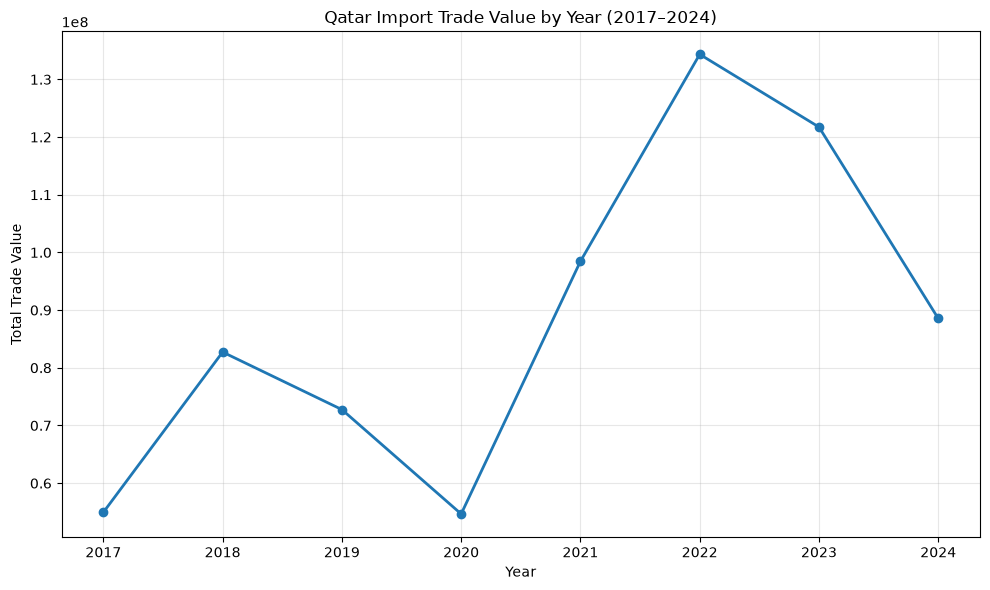

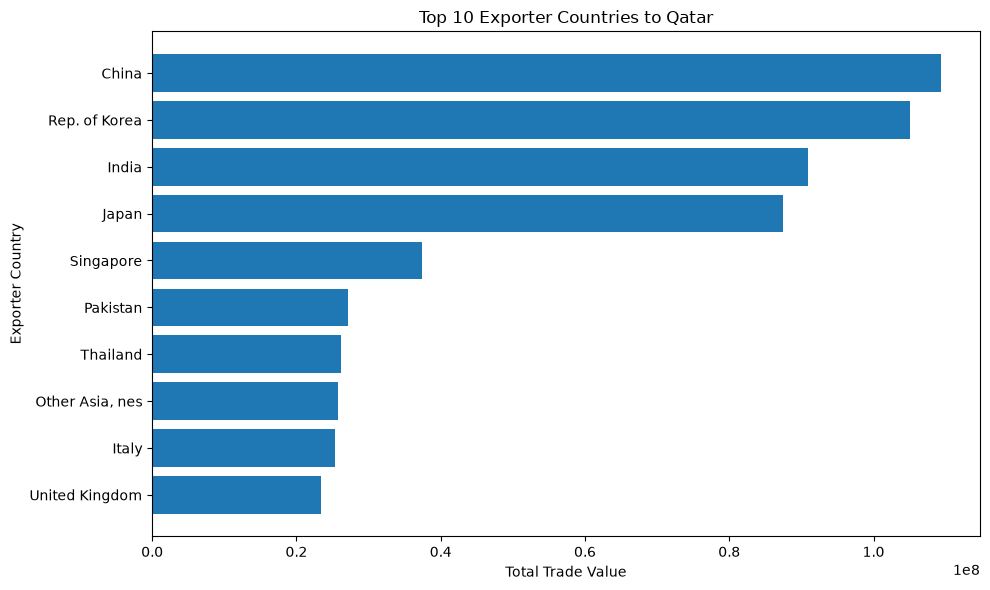

/var/folders/kd/jz6bv1rs1k989hcql0b_nl2w0000gn/T/ipykernel_2098/3074910347.py:47: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


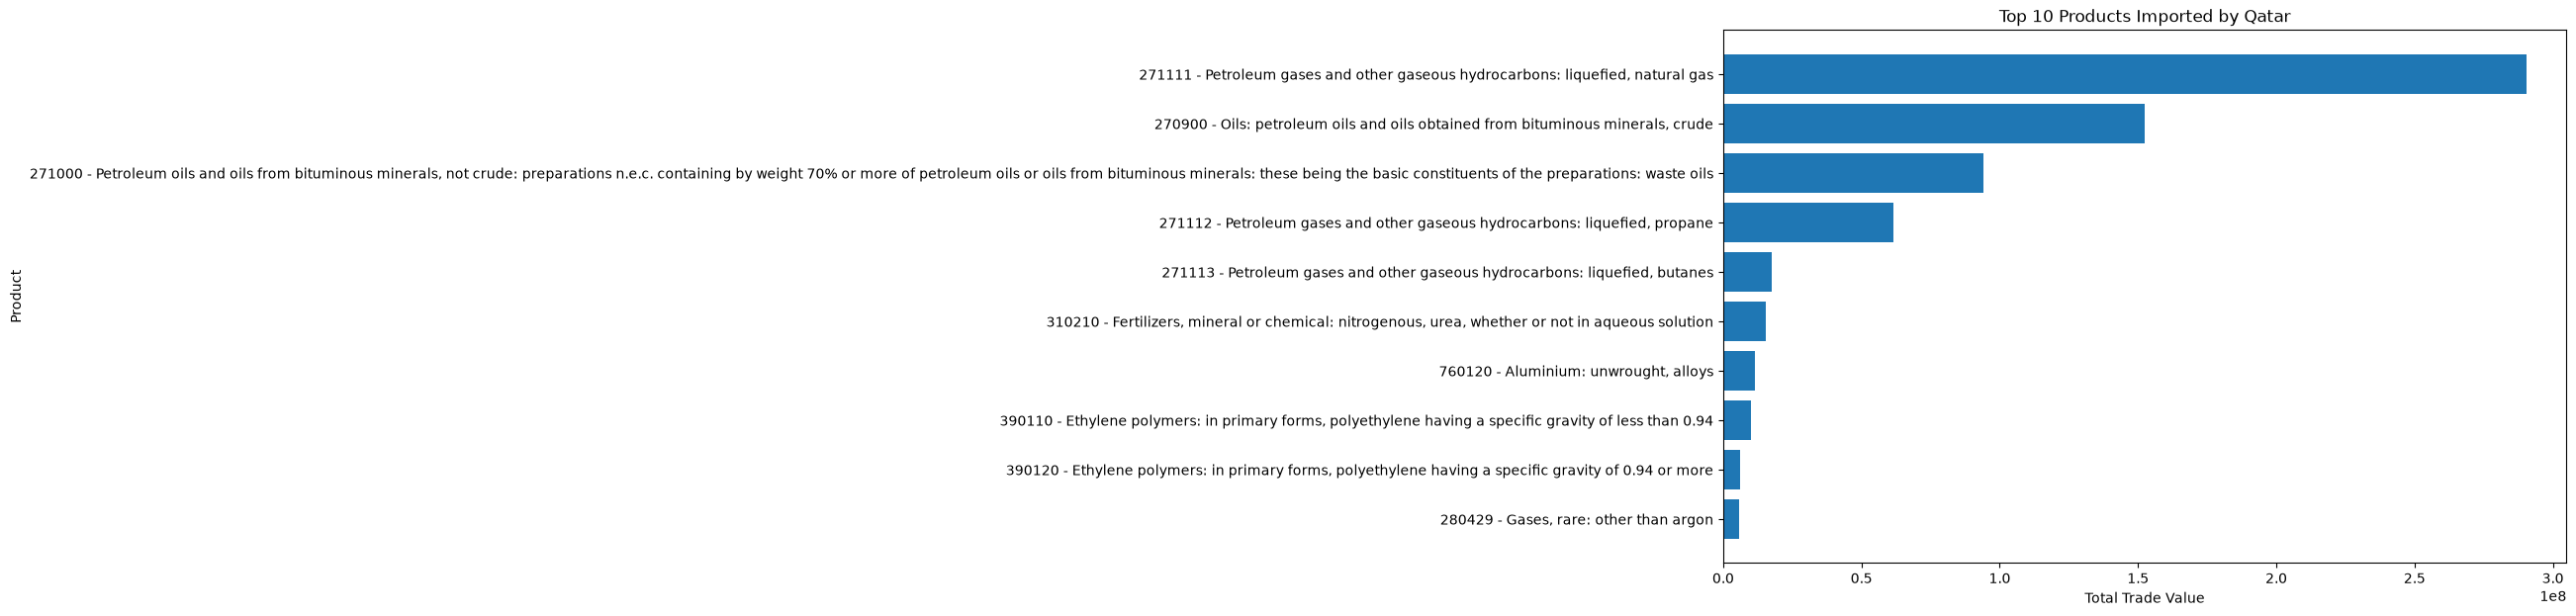

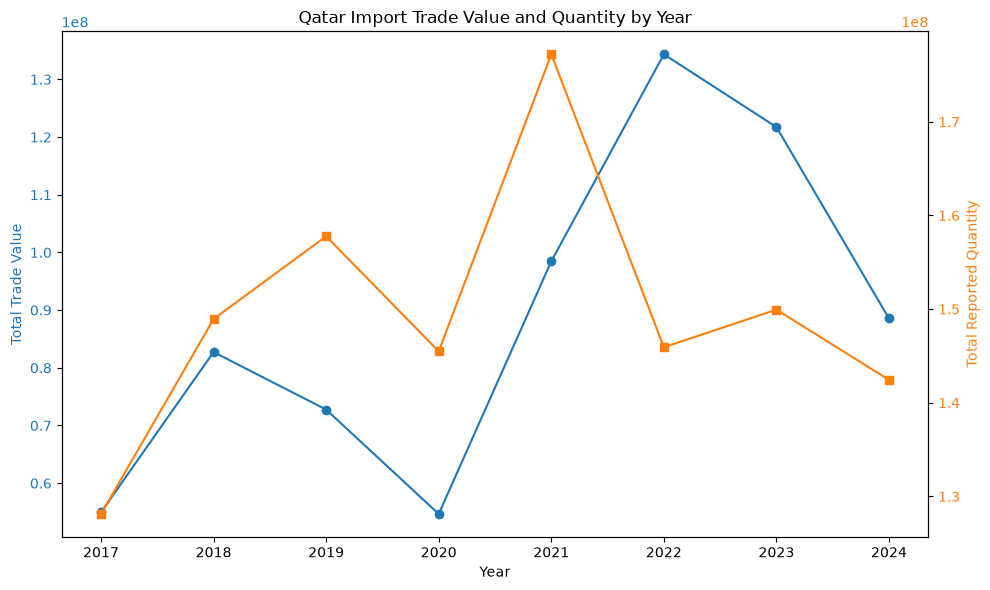


Four figures saved:
outputs/figures/figure1_trade_value_by_year.png
outputs/figures/figure2_top_exporters.png
outputs/figures/figure3_top_products.png
outputs/figures/figure4_value_and_quantity.png


In [51]:

from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

FIGURES = Path("outputs/figures")
FIGURES.mkdir(parents=True, exist_ok=True)

# Figure 1: Qatar's import trade value by year
plt.figure(figsize=(10, 6))
plt.plot(
    q1["year"], q1["total_trade_value"],
    marker="o", linewidth=2
)
plt.title("Qatar Import Trade Value by Year (2017–2024)")
plt.xlabel("Year")
plt.ylabel("Total Trade Value")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES / "figure1_trade_value_by_year.png", dpi=300)
plt.show()
plt.close()

# Figure 2: Top 10 exporter countries
plt.figure(figsize=(10, 6))
plot2 = q2.sort_values("total_trade_value")
plt.barh(plot2["exporter_name"], plot2["total_trade_value"])
plt.title("Top 10 Exporter Countries to Qatar")
plt.xlabel("Total Trade Value")
plt.ylabel("Exporter Country")
plt.tight_layout()
plt.savefig(FIGURES / "figure2_top_exporters.png", dpi=300)
plt.show()
plt.close()

# Figure 3: Top 10 products
plt.figure(figsize=(11, 7))
plot3 = q3.sort_values("total_trade_value")
labels = (
    plot3["product_code"].astype(str)
    + " - "
    + plot3["product_description"].fillna("Unknown")
)
plt.barh(labels, plot3["total_trade_value"])
plt.title("Top 10 Products Imported by Qatar")
plt.xlabel("Total Trade Value")
plt.ylabel("Product")
plt.tight_layout()
plt.savefig(FIGURES / "figure3_top_products.png", dpi=300)
plt.show()
plt.close()

# Figure 4: Trade value and quantity by year
fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.plot(
    q4["year"], q4["total_trade_value"],
    color="tab:blue", marker="o"
)
ax1.set_xlabel("Year")
ax1.set_ylabel("Total Trade Value", color="tab:blue")
ax1.tick_params(axis="y", labelcolor="tab:blue")

ax2 = ax1.twinx()
ax2.plot(
    q4["year"], q4["total_quantity"],
    color="tab:orange", marker="s"
)
ax2.set_ylabel("Total Reported Quantity", color="tab:orange")
ax2.tick_params(axis="y", labelcolor="tab:orange")

plt.title("Qatar Import Trade Value and Quantity by Year")
fig.tight_layout()
fig.savefig(FIGURES / "figure4_value_and_quantity.png", dpi=300)
plt.show()
plt.close(fig)

print("\nFour figures saved:")
for f in sorted(FIGURES.glob("figure*.png")):
    print(f)

In [55]:

from pathlib import Path
import pandas as pd

Path("outputs/reports").mkdir(parents=True, exist_ok=True)

# Row counts for the Gold star schema
gold_tables = [
    "fact_trade",
    "dim_year",
    "dim_exporter",
    "dim_product",
    "dim_importer"
]

gold_checks = []

for table in gold_tables:
    count = con.execute(
        f"SELECT COUNT(*) FROM {table}"
    ).fetchone()[0]

    gold_checks.append({
        "check_name": f"{table}_row_count",
        "result": count,
        "status": "PASS" if count > 0 else "CHECK"
    })

# Verify that the fact table matches Silver
silver_count = con.execute(
    "SELECT COUNT(*) FROM silver_trade"
).fetchone()[0]

fact_count = con.execute(
    "SELECT COUNT(*) FROM fact_trade"
).fetchone()[0]

gold_checks.append({
    "check_name": "fact_matches_silver_row_count",
    "result": fact_count == silver_count,
    "status": "PASS" if fact_count == silver_count else "FAIL"
})

# Check missing dimension keys
for table, key in [
    ("dim_year", "year"),
    ("dim_exporter", "exporter_code"),
    ("dim_product", "product_code"),
    ("dim_importer", "importer_code")
]:
    missing = con.execute(
        f"SELECT COUNT(*) FROM {table} WHERE {key} IS NULL"
    ).fetchone()[0]

    gold_checks.append({
        "check_name": f"{table}_missing_keys",
        "result": missing,
        "status": "PASS" if missing == 0 else "CHECK"
    })

gold_report = pd.DataFrame(gold_checks)

gold_report.to_csv(
    "outputs/reports/gold_validation_report.csv",
    index=False
)

print("Gold validation report saved.")
print(gold_report.to_string(index=False))

Gold validation report saved.
                   check_name result status
         fact_trade_row_count 111928   PASS
           dim_year_row_count      8   PASS
       dim_exporter_row_count    166   PASS
        dim_product_row_count   4443   PASS
       dim_importer_row_count      1   PASS
fact_matches_silver_row_count   True   PASS
        dim_year_missing_keys      0   PASS
    dim_exporter_missing_keys      0   PASS
     dim_product_missing_keys      0   PASS
    dim_importer_missing_keys      0   PASS


In [52]:
from pathlib import Path

print("Notebook working directory:", Path.cwd())

print("\nDuckDB files in this folder and subfolders:")
for f in Path.cwd().rglob("*.duckdb"):
    print(f, "|", f.stat().st_size, "bytes")

print("\nCurrent database tables:")
print(con.execute("SHOW TABLES").df())

Notebook working directory: /Users/maha/Desktop/assignment-starter-repo/assign1

DuckDB files in this folder and subfolders:
/Users/maha/Desktop/assignment-starter-repo/assign1/lakehouse_empty_backup.duckdb | 0 bytes
/Users/maha/Desktop/assignment-starter-repo/assign1/lakehouse.duckdb | 949497856 bytes

Current database tables:
                       name
0              bronze_trade
1   country_lookup_clean_df
2         country_lookup_df
3      country_lookup_final
4              dim_exporter
5              dim_importer
6               dim_product
7                  dim_year
8                fact_trade
9         product_lookup_df
10     product_lookup_final
11           silver_country
12           silver_product
13             silver_trade


In [54]:

from pathlib import Path

required_files = [
    "data/bronze/bronze_trade.parquet",
    "data/silver/silver_trade.parquet",
    "data/gold/fact_trade.parquet",
    "data/gold/dim_year.parquet",
    "data/gold/dim_exporter.parquet",
    "data/gold/dim_product.parquet",
    "data/gold/dim_importer.parquet",
    "outputs/reports/load_report.csv",
    "outputs/reports/silver_quality_report.csv",
    "outputs/query_results/q1_trade_value_by_year.csv",
    "outputs/query_results/q2_top_exporters.csv",
    "outputs/query_results/q3_top_products.csv",
    "outputs/query_results/q4_value_and_quantity_by_year.csv",
    "outputs/figures/figure1_trade_value_by_year.png",
    "outputs/figures/figure2_top_exporters.png",
    "outputs/figures/figure3_top_products.png",
    "outputs/figures/figure4_value_and_quantity.png",
]

missing = [f for f in required_files if not Path(f).is_file()]

print(f"Required files checked: {len(required_files)}")
print(f"Missing files: {len(missing)}")

if missing:
    for f in missing:
        print("MISSING:", f)
else:
    print("All expected output files are present.")

Required files checked: 17
Missing files: 0
All expected output files are present.


In [56]:
from pathlib import Path

for f in Path("data/bronze").rglob("*"):
    if f.is_file():
        print(f"{f}: {f.stat().st_size / (1024**2):.1f} MB")

data/bronze/bronze_trade.parquet: 969.1 MB
